## Model Error Mapping
Assess model output errors spatially.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np

In [2]:
# Load the CSV data
df = pd.read_csv('../combined_results.csv')
df.head()

,site,latitude,longitude,output_years,bias_s00000000_ghec,rmse_s00000000_ghec,model_snow_days_s00000000_ghec,snotel_snow_days,mean_snotel_swe,var_snotel_swe,bias_s01011010_gbc,rmse_s01011010_gbc,model_snow_days_s01011010_gbc,bias_s01011010_ghec,rmse_s01011010_ghec,model_snow_days_s01011010_ghec,bias_s01011010_ghelaps,rmse_s01011010_ghelaps,model_snow_days_s01011010_ghelaps
0,Forestdale Creek,38.68,-119.96,16.0,-95.3,168.5,2909,3065,277.6,150622.6,7.2,63.5,3053,131.3,251.7,3678,55.8,106.6,3152
1,Horse Meadow,38.84,-119.89,11.2,-22.0,66.2,1627,1704,127.6,38347.5,-8.3,49.7,1601,49.2,110.3,1984,19.7,64.6,1723
2,Burnside Lake,38.72,-119.89,16.0,-7.2,89.5,3124,3055,196.3,83372.0,34.3,75.5,3081,133.7,254.1,3760,78.0,150.9,3269
3,Summit Meadow,38.40,-119.54,9.2,-9.4,67.5,1186,1153,103.5,25719.7,5.7,31.2,1176,67.9,140.2,1468,38.3,84.2,1312
4,Carson Pass,38.69,-120.00,14.0,-67.7,124.9,2500,2705,233.7,107471.6,-12.9,56.2,2585,87.3,205.2,3138,28.2,84.4,2719


In [3]:
# Remove sites where 'output_years' < 5
df = df[df['output_years'] >= 5]

### RMSE Calculation

In [ ]:
# Create new df for rmse calculations
rmse_df = df[['site', 'latitude', 'longitude', 'mean_snotel_swe', 'var_snotel_swe', 'rmse_s00000000_ghec', 'rmse_s01011010_ghec', 'rmse_s01011010_ghelaps', 'rmse_s01011010_gbc']].copy()


In [ ]:
# Calculate drmse for each model compared to baseline rmse_s00000000_ghec
baseline_rmse = rmse_df['rmse_s00000000_ghec']
rmse_df['drmse_s01011010_ghec'] = rmse_df['rmse_s01011010_ghec'] - baseline_rmse
rmse_df['drmse_s01011010_ghelaps'] = rmse_df['rmse_s01011010_ghelaps'] - baseline_rmse
rmse_df['drmse_s01011010_gbc'] = rmse_df['rmse_s01011010_gbc'] - baseline_rmse

In [ ]:
# Create figure with 2x2 grid of subplots
fig = plt.figure(figsize=(16, 14))

# Define the columns and titles to plot
columns = ['rmse_s00000000_ghec', 'drmse_s01011010_gbc', 'drmse_s01011010_ghec', 'drmse_s01011010_ghelaps']
titles = ['RMSE Baseline', 'dRMSE (GBC)', 'dRMSE (GHEC)', 'dRMSE (GHELAPS)']

# Set color scale limits
vmax_baseline = 250  # Different scale for baseline RMSE
vmin_baseline = 0
vmax_drmse = 200     # Symmetric scale for drmse plots
vmin_drmse = -200

# Create four subplots in 2x2 grid
for pos, column in enumerate(zip(columns, titles), 1):
    column, title = column  # Unpack from zip
    ax = plt.subplot(2, 2, pos, projection=ccrs.PlateCarree())
    
    # Set extent for Western United States
    ax.set_extent([-125, -102, 31, 49], crs=ccrs.PlateCarree())
    
    # Add map features
    ax.add_feature(cfeature.STATES, linewidth=0.5, edgecolor='black')
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
    ax.add_feature(cfeature.BORDERS, linewidth=0.5)
    ax.add_feature(cfeature.LAND, facecolor='lightgray', alpha=0.3)
    
    # Use different color scales for baseline vs drmse
    if pos == 1:  # Baseline RMSE
        vmin, vmax = vmin_baseline, vmax_baseline
        cmap = 'viridis'
    else:  # drmse plots
        vmin, vmax = vmin_drmse, vmax_drmse
        cmap = 'coolwarm'
    
    # Plot the data points
    scatter = ax.scatter(rmse_df['longitude'], rmse_df['latitude'],
                         c=rmse_df[column],
                         s=50,
                         alpha=0.8,
                         cmap=cmap,
                         vmin=vmin,
                         vmax=vmax,
                         transform=ccrs.PlateCarree(),
                         edgecolors='black',
                         linewidth=0.5)
    
    # Add colorbar
    cbar = plt.colorbar(scatter, ax=ax, orientation='vertical', pad=0.05, shrink=0.8)
    cbar.set_label(column, fontsize=10, fontweight='bold')
    
    # Add gridlines
    gl = ax.gridlines(draw_labels=True, linewidth=0.5, alpha=0.5, linestyle='--')
    gl.top_labels = False
    gl.right_labels = False
    
    # Add title
    ax.set_title(title, fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

# Display basic info about the data
print(f"Total data points: {len(rmse_df)}")
print(f"\nValue ranges:")
for column in columns:
    print(f"{column}: {rmse_df[column].min():.2f} to {rmse_df[column].max():.2f}")
print(f"\nColormap ranges:")
print(f"Baseline RMSE: {vmin_baseline} to {vmax_baseline}")
print(f"dRMSE plots: {vmin_drmse} to {vmax_drmse}")

In order to compare RMSE across sites it needs to be normalized. Following Krinner et al. (2018) we normalize RMSE by the standard deviation of the observations at each site.

In [ ]:
rmse_df['nrmse_s00000000_ghec'] = rmse_df['rmse_s00000000_ghec'] / np.sqrt(rmse_df['var_snotel_swe'])
rmse_df['nrmse_s01011010_ghec'] = rmse_df['rmse_s01011010_ghec'] / np.sqrt(rmse_df['var_snotel_swe'])
rmse_df['nrmse_s01011010_ghelaps'] = rmse_df['rmse_s01011010_ghelaps'] / np.sqrt(rmse_df['var_snotel_swe'])
rmse_df['nrmse_s01011010_gbc'] = rmse_df['rmse_s01011010_gbc'] / np.sqrt(rmse_df['var_snotel_swe'])

In [ ]:
# Alternative, use mean SWE for normalization
rmse_df['nrmse_s00000000_ghec'] = rmse_df['rmse_s00000000_ghec'] / rmse_df['mean_snotel_swe']
rmse_df['nrmse_s01011010_ghec'] = rmse_df['rmse_s01011010_ghec'] / rmse_df['mean_snotel_swe']
rmse_df['nrmse_s01011010_ghelaps'] = rmse_df['rmse_s01011010_ghelaps'] / rmse_df['mean_snotel_swe']
rmse_df['nrmse_s01011010_gbc'] = rmse_df['rmse_s01011010_gbc'] / rmse_df['mean_snotel_swe']

In [ ]:
# Average nrmse for each model across all sites
nrmse_summary = {
    'Model': ['GHEC Baseline', 'GBC', 'GHEC downscaled', 'GHELAPS'],
    'Average NRMSE': [
        rmse_df['nrmse_s00000000_ghec'].mean(),
        rmse_df['nrmse_s01011010_gbc'].mean(),
        rmse_df['nrmse_s01011010_ghec'].mean(),
        rmse_df['nrmse_s01011010_ghelaps'].mean()
    ]
}
print(pd.DataFrame(nrmse_summary))

In [ ]:
# Create figure with 2x2 grid of subplots for normalized RMSE
fig = plt.figure(figsize=(16, 14))

# Define the columns and titles to plot
columns = ['nrmse_s00000000_ghec', 'nrmse_s01011010_gbc', 'nrmse_s01011010_ghec', 'nrmse_s01011010_ghelaps']
titles = ['nRMSE Baseline', 'nRMSE (GBC)', 'nRMSE (GHEC)', 'nRMSE (GHELAPS)']

# Set color scale limits centered on 1
vmin = 0
vmax = 2

# Create four subplots in 2x2 grid
for pos, (column, title) in enumerate(zip(columns, titles), 1):
    ax = plt.subplot(2, 2, pos, projection=ccrs.PlateCarree())
    
    # Set extent for Western United States
    ax.set_extent([-125, -102, 31, 49], crs=ccrs.PlateCarree())
    
    # Add map features
    ax.add_feature(cfeature.STATES, linewidth=0.5, edgecolor='black')
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
    ax.add_feature(cfeature.BORDERS, linewidth=0.5)
    ax.add_feature(cfeature.LAND, facecolor='lightgray', alpha=0.3)
    
    # Plot the data points
    scatter = ax.scatter(rmse_df['longitude'], rmse_df['latitude'],
                         c=rmse_df[column],
                         s=50,
                         alpha=0.8,
                         cmap='coolwarm',
                         vmin=vmin,
                         vmax=vmax,
                         transform=ccrs.PlateCarree(),
                         edgecolors='black',
                         linewidth=0.5)
    
    # Add colorbar
    cbar = plt.colorbar(scatter, ax=ax, orientation='vertical', pad=0.05, shrink=0.8)
    cbar.set_label(column, fontsize=10, fontweight='bold')
    
    # Add gridlines
    gl = ax.gridlines(draw_labels=True, linewidth=0.5, alpha=0.5, linestyle='--')
    gl.top_labels = False
    gl.right_labels = False
    
    # Add title
    ax.set_title(title, fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

# Display basic info about the data
print(f"Total data points: {len(rmse_df)}")
print(f"\nValue ranges:")
for column in columns:
    print(f"{column}: {rmse_df[column].min():.2f} to {rmse_df[column].max():.2f}")
print(f"\nShared colormap range: {vmin} to {vmax} (centered on 1)")

In [ ]:
# Plot focused on NM
fig = plt.figure(figsize=(16, 14))
# Create four subplots in 2x2 grid
for pos, (column, title) in enumerate(zip(columns, titles), 1):
    ax = plt.subplot(2, 2, pos, projection=ccrs.PlateCarree())
    
    # Set extent for New Mexico
    ax.set_extent([-109.5, -104.5, 32, 38], crs=ccrs.PlateCarree())
    
    # Add map features
    ax.add_feature(cfeature.STATES, linewidth=0.5, edgecolor='black')
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
    ax.add_feature(cfeature.BORDERS, linewidth=0.5)
    ax.add_feature(cfeature.LAND, facecolor='lightgray', alpha=0.3)
    
    # Plot the data points
    scatter = ax.scatter(df['longitude'], df['latitude'],
                         c=df[column],
                         s=50,
                         alpha=0.8,
                         cmap='coolwarm',
                         vmin=vmin,
                         vmax=vmax,
                         transform=ccrs.PlateCarree(),
                         edgecolors='black',
                         linewidth=0.5)
    
    # Add colorbar
    cbar = plt.colorbar(scatter, ax=ax, orientation='vertical', pad=0.05, shrink=0.8)
    cbar.set_label(column, fontsize=10, fontweight='bold')
    
    # Add gridlines
    gl = ax.gridlines(draw_labels=True, linewidth=0.5, alpha=0.5, linestyle='--')
    gl.top_labels = False
    gl.right_labels = False
    
    # Add title
    ax.set_title(title + ' (New Mexico)', fontsize=14, fontweight='bold')

### Normalized Bias Calculation
Normalize bias by dividing by the mean SWE at each site.

In [4]:
# Create a dataframe for bias
bias_df = df[['site', 'latitude', 'longitude', 'mean_snotel_swe', 'var_snotel_swe', 'bias_s00000000_ghec', 'bias_s01011010_ghec', 'bias_s01011010_ghelaps', 'bias_s01011010_gbc']].copy()

In [5]:
bias_df['nbias_s00000000_ghec'] = bias_df['bias_s00000000_ghec'] / bias_df['mean_snotel_swe']
bias_df['nbias_s01011010_ghec'] = bias_df['bias_s01011010_ghec'] / bias_df['mean_snotel_swe']
bias_df['nbias_s01011010_ghelaps'] = bias_df['bias_s01011010_ghelaps'] / bias_df['mean_snotel_swe']
bias_df['nbias_s01011010_gbc'] = bias_df['bias_s01011010_gbc'] / bias_df['mean_snotel_swe']

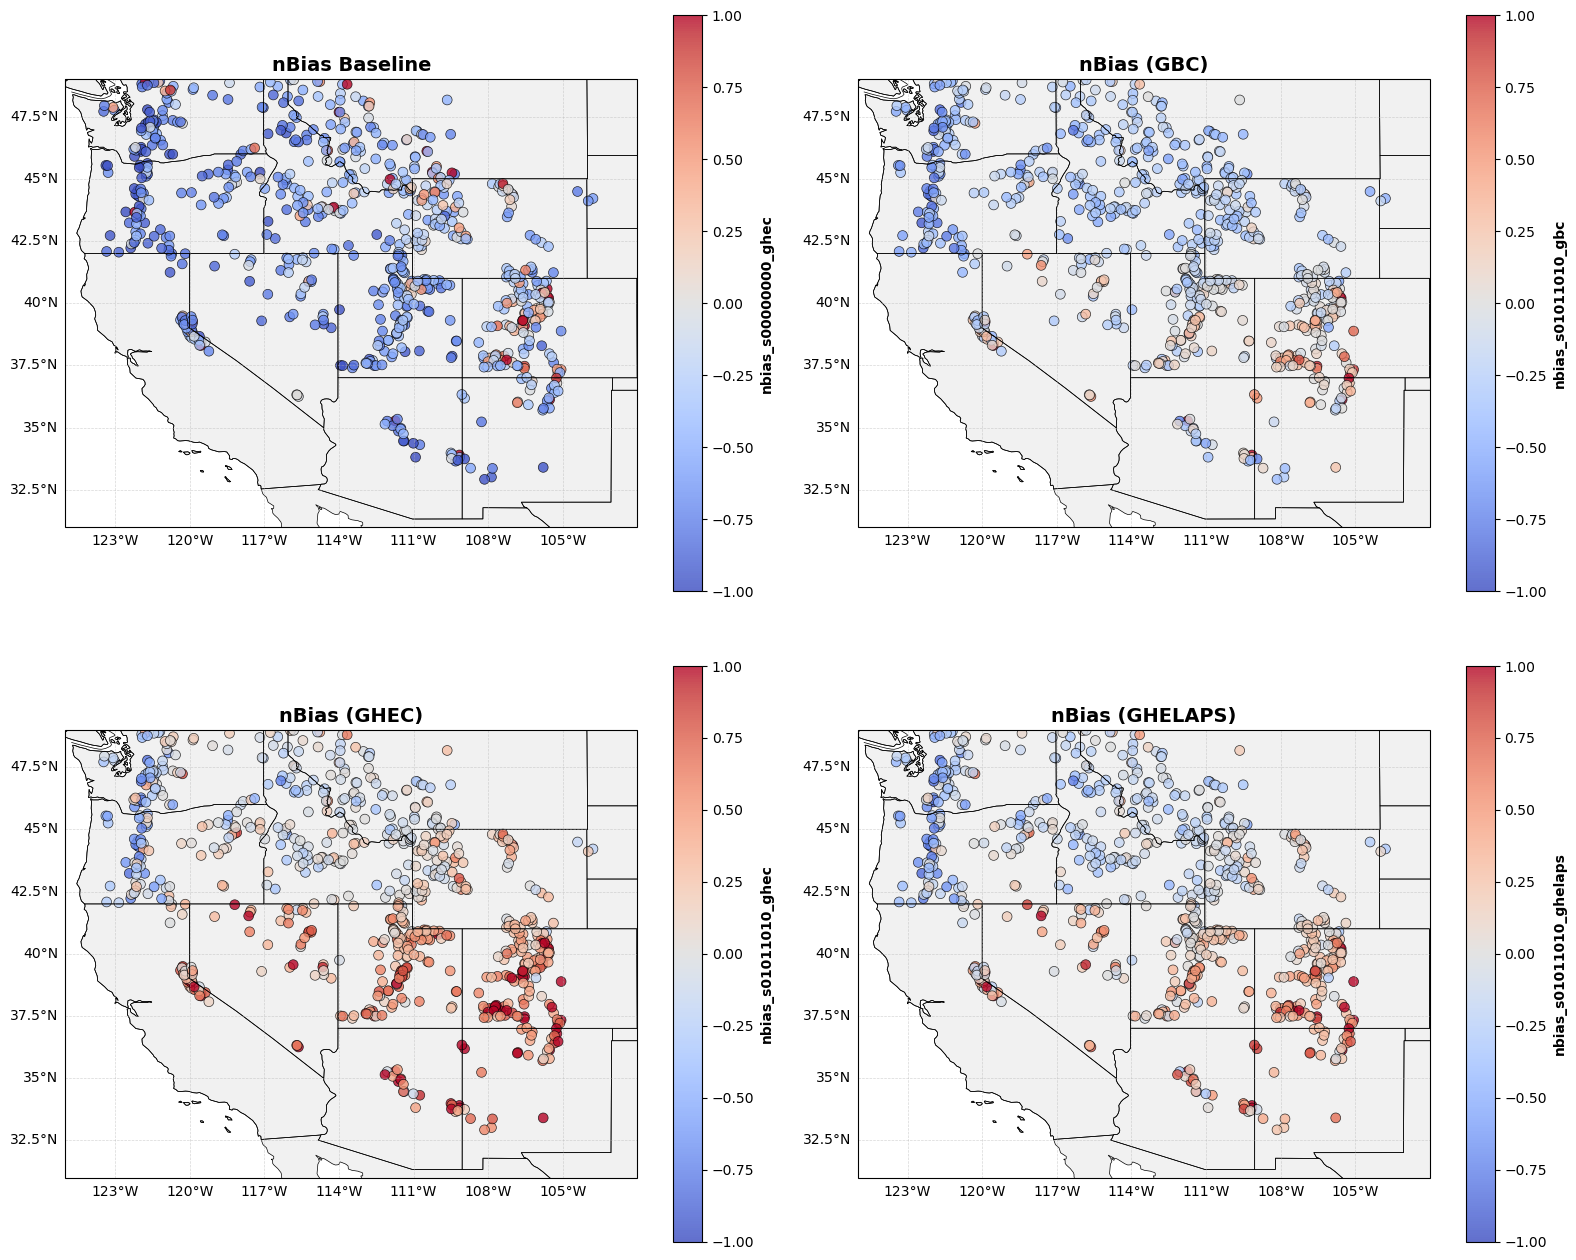

Total data points: 765

Value ranges:
nbias_s00000000_ghec: -1.00 to 3.76
nbias_s01011010_gbc: -0.97 to 2.01
nbias_s01011010_ghec: -0.96 to 37.46
nbias_s01011010_ghelaps: -0.96 to 3.10

Shared colormap range: -1 to 1 (centered on 0)


In [6]:
# Create figure with 2x2 grid of subplots for normalized bias
fig = plt.figure(figsize=(16, 14))

# Define the columns and titles to plot
columns = ['nbias_s00000000_ghec', 'nbias_s01011010_gbc', 'nbias_s01011010_ghec', 'nbias_s01011010_ghelaps']
titles = ['nBias Baseline', 'nBias (GBC)', 'nBias (GHEC)', 'nBias (GHELAPS)']

# Set color scale limits centered on 0
vmin = -1
vmax = 1

# Create four subplots in 2x2 grid
for pos, (column, title) in enumerate(zip(columns, titles), 1):
    ax = plt.subplot(2, 2, pos, projection=ccrs.PlateCarree())
    
    # Set extent for Western United States
    ax.set_extent([-125, -102, 31, 49], crs=ccrs.PlateCarree())
    
    # Add map features
    ax.add_feature(cfeature.STATES, linewidth=0.5, edgecolor='black')
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
    ax.add_feature(cfeature.BORDERS, linewidth=0.5)
    ax.add_feature(cfeature.LAND, facecolor='lightgray', alpha=0.3)
    
    # Plot the data points
    scatter = ax.scatter(bias_df['longitude'], bias_df['latitude'],
                         c=bias_df[column],
                         s=50,
                         alpha=0.8,
                         cmap='coolwarm',
                         vmin=vmin,
                         vmax=vmax,
                         transform=ccrs.PlateCarree(),
                         edgecolors='black',
                         linewidth=0.5)
    
    # Add colorbar
    cbar = plt.colorbar(scatter, ax=ax, orientation='vertical', pad=0.05, shrink=0.8)
    cbar.set_label(column, fontsize=10, fontweight='bold')
    
    # Add gridlines
    gl = ax.gridlines(draw_labels=True, linewidth=0.5, alpha=0.5, linestyle='--')
    gl.top_labels = False
    gl.right_labels = False
    
    # Add title
    ax.set_title(title, fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

# Display basic info about the data
print(f"Total data points: {len(bias_df)}")
print(f"\nValue ranges:")
for column in columns:
    print(f"{column}: {bias_df[column].min():.2f} to {bias_df[column].max():.2f}")
print(f"\nShared colormap range: {vmin} to {vmax} (centered on 0)")

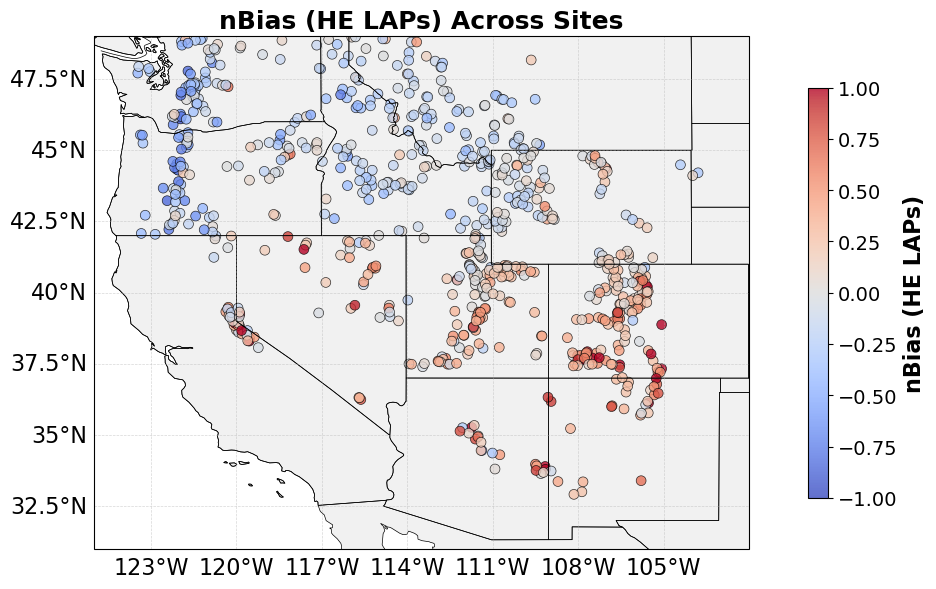

In [10]:
# Select Bias Plot
# Single plot of select nBias for presentation purposes
fig = plt.figure(figsize=(12, 6))
ax = plt.subplot(1, 1, 1, projection=ccrs.PlateCarree())
ax.set_extent([-125, -102, 31, 49], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.STATES, linewidth=0.5, edgecolor='black')
ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
ax.add_feature(cfeature.BORDERS, linewidth=0.5)
ax.add_feature(cfeature.LAND, facecolor='lightgray', alpha=0.3)
scatter = ax.scatter(bias_df['longitude'], bias_df['latitude'],
                     c=bias_df['nbias_s01011010_ghelaps'],
                     s=50,
                     alpha=0.8,
                     cmap='coolwarm',
                     vmin=-1,
                     vmax=1,
                     transform=ccrs.PlateCarree(),
                     edgecolors='black',
                     linewidth=0.5)
cbar = plt.colorbar(scatter, ax=ax, orientation='vertical', pad=0.05, shrink=0.8)
cbar.set_label('nBias (HE LAPs)', fontsize=16, fontweight='bold')
cbar.ax.tick_params(labelsize=14)
gl = ax.gridlines(draw_labels=True, linewidth=0.5, alpha=0.5, linestyle='--')
gl.top_labels = False
gl.right_labels = False
gl.xlabel_style = {'size': 16}
gl.ylabel_style = {'size': 16}
ax.set_title('nBias (HE LAPs) Across Sites', fontsize=18, fontweight='bold')
plt.tight_layout()

### Snow Days

In [ ]:
# Create a dataframe for snow days
snow_days_df = df[['site',
                   'latitude',
                   'longitude',
                   'output_years',
                   'mean_snotel_swe',
                   'var_snotel_swe',
                   'snotel_snow_days',
                   'model_snow_days_s00000000_ghec',
                   'model_snow_days_s01011010_ghec',
                   'model_snow_days_s01011010_ghelaps',
                   'model_snow_days_s01011010_gbc']].copy()

In [ ]:
# Calculate various differences normalized by number of years
snow_days_df['dsnow_days_s00000000_ghec'] = (snow_days_df['model_snow_days_s00000000_ghec'] - snow_days_df['snotel_snow_days']) / snow_days_df['output_years']
snow_days_df['dsnow_days_s01011010_ghec'] = (snow_days_df['model_snow_days_s01011010_ghec'] - snow_days_df['snotel_snow_days']) / snow_days_df['output_years']
snow_days_df['dsnow_days_s01011010_ghelaps'] = (snow_days_df['model_snow_days_s01011010_ghelaps'] - snow_days_df['snotel_snow_days']) / snow_days_df['output_years']
snow_days_df['dsnow_days_s01011010_gbc'] = (snow_days_df['model_snow_days_s01011010_gbc'] - snow_days_df['snotel_snow_days']) / snow_days_df['output_years']

snow_days_df['dsnow_days_hec_helaps'] = (snow_days_df['model_snow_days_s01011010_ghec'] - snow_days_df['model_snow_days_s01011010_ghelaps']) / snow_days_df['output_years']

In [ ]:
# Create figure with 2x2 grid of subplots for normalized bias
fig = plt.figure(figsize=(16, 14))

# Define the columns and titles to plot
columns = ['dsnow_days_s00000000_ghec', 'dsnow_days_s01011010_gbc', 'dsnow_days_s01011010_ghelaps', 'dsnow_days_hec_helaps']
titles = ['dSnow Days Baseline', 'dSnow Days (GBC)', 'dSnow Days (GHELAPS)', 'dSnow Days (HE - HELAPS)']

# Set color scale limits centered on 0
vmin, vmax = (-100, 100)


# Create four subplots in 2x2 grid
for pos, (column, title) in enumerate(zip(columns, titles), 1):
    ax = plt.subplot(2, 2, pos, projection=ccrs.PlateCarree())
    
    # Set extent for Western United States
    ax.set_extent([-125, -102, 31, 49], crs=ccrs.PlateCarree())
    
    # Add map features
    ax.add_feature(cfeature.STATES, linewidth=0.5, edgecolor='black')
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
    ax.add_feature(cfeature.BORDERS, linewidth=0.5)
    ax.add_feature(cfeature.LAND, facecolor='lightgray', alpha=0.3)
    
    # Plot the data points
    scatter = ax.scatter(snow_days_df['longitude'], snow_days_df['latitude'],
                         c=snow_days_df[column],
                         s=50,
                         alpha=0.8,
                         cmap='coolwarm',
                         vmin=vmin,
                         vmax=vmax,
                         transform=ccrs.PlateCarree(),
                         edgecolors='black',
                         linewidth=0.5)
    
    # Add colorbar
    cbar = plt.colorbar(scatter, ax=ax, orientation='vertical', pad=0.05, shrink=0.8)
    cbar.set_label(column, fontsize=10, fontweight='bold')
    
    # Add gridlines
    gl = ax.gridlines(draw_labels=True, linewidth=0.5, alpha=0.5, linestyle='--')
    gl.top_labels = False
    gl.right_labels = False
    
    # Add title
    ax.set_title(title, fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

# Display basic info about the data
print(f"Total data points: {len(snow_days_df)}")
print(f"\nValue ranges:")
for column in columns:
    print(f"{column}: {snow_days_df[column].min():.2f} to {snow_days_df[column].max():.2f}")
print(f"\nShared colormap range: {vmin} to {vmax} (centered on 0)")

In [ ]:
# Histogram of dsnow_days_hec_helaps
plt.figure(figsize=(10, 6))
plt.hist(snow_days_df['dsnow_days_hec_helaps'], bins=30, color='skyblue', edgecolor='black')
plt.title('Histogram of dSnow Days (HEC - HELAPS)', fontsize=14, fontweight='bold')
plt.xlabel('dSnow Days per Year', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)

# Plot mean and stddev lines
mean_diff = snow_days_df['dsnow_days_hec_helaps'].mean()
stddev_diff = snow_days_df['dsnow_days_hec_helaps'].std()
plt.axvline(mean_diff, color='red', linestyle='dashed', linewidth=2, label=f'Mean: {mean_diff:.2f}')
plt.axvline(mean_diff + stddev_diff, color='green', linestyle='dashed', linewidth=2, label=f'Std Dev: {stddev_diff:.2f}')
plt.axvline(mean_diff - stddev_diff, color='green', linestyle='dashed', linewidth=2)
plt.legend()


Some output for further processing:

- Project the locations for use in geostats (separate notebook)

In [ ]:
# Convert lat/lon to Albers Equal Area Conic projection
from pyproj import Transformer

# EPSG:5070 is NAD83 / Conus Albers - designed for continental US
# This projection preserves area and is suitable for distance calculations
transformer = Transformer.from_crs("EPSG:4326", "EPSG:5070", always_xy=True)

# Transform coordinates (returns coordinates in meters)
df['x_albers'], df['y_albers'] = transformer.transform(
    df['longitude'].values, 
    df['latitude'].values
)

print("Albers Equal Area Conic coordinates added to dataframe")
print(f"\nX range: {df['x_albers'].min():.0f} to {df['x_albers'].max():.0f} meters")
print(f"Y range: {df['y_albers'].min():.0f} to {df['y_albers'].max():.0f} meters")
print(f"\nSample of converted coordinates:")
print(df[['site', 'latitude', 'longitude', 'x_albers', 'y_albers']].head())

In [ ]:
df[['x_albers', 'y_albers']].plot(kind='scatter', x='x_albers', y='y_albers', figsize=(8, 6))

Export key data for geostatistical analysis

In [ ]:
df[['site', 'output_years','x_albers', 'y_albers','nbias_s01011010_ghelaps', 'nbias_s01011010_gbc','nrmse_s01011010_ghelaps', 'nrmse_s01011010_gbc']].to_csv('../nresults_albers.csv', index=False)